In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import resample

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GRU, Dense, Dropout, Bidirectional, Masking
from tensorflow.keras.utils import to_categorical

In [3]:
train_data = pd.read_csv("mitbih_train.csv", header=None)
test_data = pd.read_csv("mitbih_test.csv", header=None)

print(f"num of train data: {len(train_data)}")
print(f"num of test data: {len(test_data)}")

num of train data: 87554
num of test data: 21892


In [4]:
def balance_classes(df, target_count=20000):
    balanced_df = pd.DataFrame()
    for i in range(5):
        class_subset = df[df[187] == i]
        is_upsampling = i != 0 
        resampled_subset = resample(class_subset, 
                                    replace=is_upsampling, 
                                    n_samples=target_count, 
                                    random_state=123)
        balanced_df = pd.concat([balanced_df, resampled_subset])
    return balanced_df

train_balanced = balance_classes(train_data)

print(train_balanced[187].value_counts())

187
0.0    20000
1.0    20000
2.0    20000
3.0    20000
4.0    20000
Name: count, dtype: int64


In [5]:
X_train = train_balanced.iloc[:, :-1].values.astype('float32')
y_train = train_balanced.iloc[:, -1].values.astype('int')
X_test = test_data.iloc[:, :-1].values.astype('float32')
y_test = test_data.iloc[:, -1].values.astype('int')

y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print(f"\nFinal Training Shape: {X_train.shape}")


Final Training Shape: (100000, 187, 1)


In [6]:
def build_model(input_shape):
    inputs = Input(shape=input_shape)

    x = Masking(mask_value=0.0)(inputs)

    x = Bidirectional(GRU(64, return_sequences=True))(x)
    x = GRU(64, return_sequences=False)(x)

    x = Dense(64, activation='relu')(x)
    x = Dropout(0.2)(x)
    outputs = Dense(5, activation='softmax')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_model((X_train.shape[1], 1))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 187, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 187, 1)    │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking (Masking)   │ (None, 187, 1)    │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 187)       │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 187, 128)  │     25,728 │ masking[0][0],    │
│ (Bidirectional)     │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 64)        │     37,248 │ bidirectional[0]… │
│                     │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 5)         │        325 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 67,461 (263.52 KB)

 Trainable params: 67,461 (263.52 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

history = model.fit(
    X_train, y_train_cat,
    epochs=30,
    batch_size=128,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1
) 

Epoch 1/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 222s 328ms/step - accuracy: 0.6603 - loss: 0.8999 - val_accuracy: 0.8107 - val_loss: 0.7041 - learning_rate: 0.0010
Epoch 2/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 258s 388ms/step - accuracy: 0.8372 - loss: 0.4565 - val_accuracy: 0.8759 - val_loss: 0.4461 - learning_rate: 0.0010
Epoch 3/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 268s 403ms/step - accuracy: 0.8765 - loss: 0.3470 - val_accuracy: 0.8739 - val_loss: 0.4016 - learning_rate: 0.0010
Epoch 4/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 304s 457ms/step - accuracy: 0.8982 - loss: 0.2860 - val_accuracy: 0.8996 - val_loss: 0.3003 - learning_rate: 0.0010
Epoch 5/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 231s 347ms/step - accuracy: 0.9103 - loss: 0.2496 - val_accuracy: 0.8897 - val_loss: 0.3494 - learning_rate: 0.0010
Epoch 6/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 217s 326ms/step - accuracy: 0.9217 - loss: 0.2184 - val_accuracy: 0.9183 - val_loss: 0.2537 - learning_rate: 0.0010
Epoch 7/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 241s 363ms/step - accura

In [8]:
# Save the trained model in Keras format
model.save('ecg_mitbih_model.keras')
print("Model saved successfully as 'ecg_mitbih_model.keras'")

Model saved successfully as 'ecg_mitbih_model.keras'


685/685 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step

--- Final Classification Report ---
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98     18118
      S-type       0.63      0.84      0.72       556
      V-type       0.90      0.96      0.92      1448
      F-type       0.51      0.86      0.64       162
     Unknown       0.98      0.97      0.97      1608

    accuracy                           0.97     21892
   macro avg       0.80      0.92      0.85     21892
weighted avg       0.97      0.97      0.97     21892



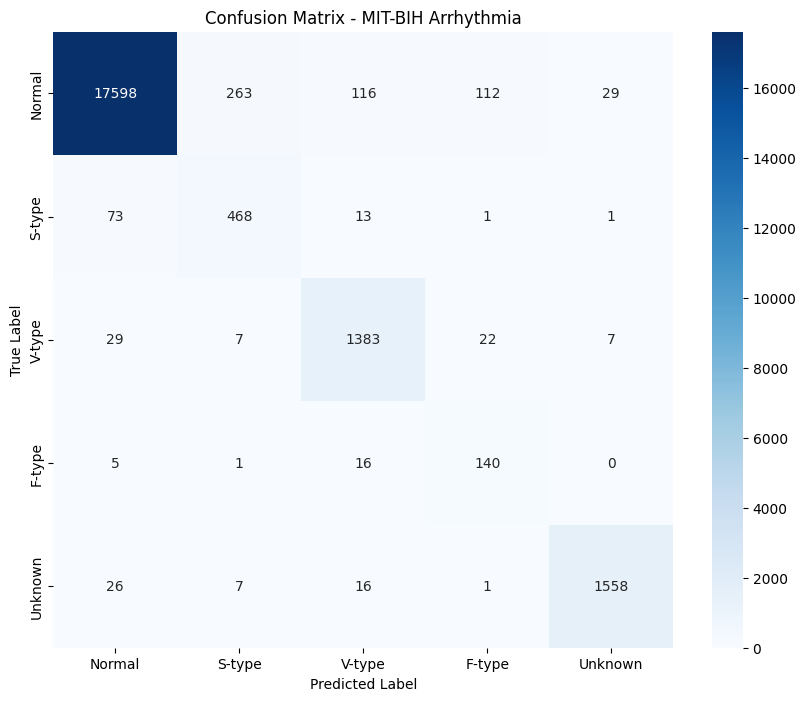

In [9]:
y_pred = np.argmax(model.predict(X_test), axis=1)
classes = ['Normal', 'S-type', 'V-type', 'F-type', 'Unknown']

print("\n--- Final Classification Report ---")
print(classification_report(y_test, y_pred, target_names=classes))

plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix - MIT-BIH Arrhythmia')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()